# Helmholtz near-field evaluation

This notebook contains two experiments on the same curved FE geometry and the same interpolated Helmholtz traces.

1. **Helmholtz representation formula.** We compare the complete direct representation
   $$
   u_h(\boldsymbol x)=S(j_h)(\boldsymbol x)+D(m_h)(\boldsymbol x)
   $$
   with the geometry-independent exact point-source field. This experiment contains the propagated trace-interpolation error and the quadrature error, and the two layer-potential errors may cancel or reinforce each other.

2. **Double-layer jump.** We approach an interior point of one fixed surface element symmetrically from both sides and compare
   $$
   D(m_h)(\boldsymbol x_\delta^{\rm out})-D(m_h)(\boldsymbol x_\delta^{\rm in})
   \longrightarrow m_h(\boldsymbol y_0).
   $$
   The limiting value is exact for the discrete trace \(m_h\), so this experiment has no trace-interpolation error. It tests the near-field integration of the double-layer potential directly.

The geometry, mesh, trace spaces, and interpolated Cauchy data are created once and reused in both experiments. The three integration methods are named consistently throughout:

- **naive Gauss**: Gaussian quadrature on the complete integrand;
- **Duffy only**: Duffy quadrature on the complete integrand for nearfield elements;
- **analytical + Duffy**: analytical planar Laplace extraction plus Duffy quadrature for the numerical remainder.

The Helmholtz kernel correction is included in every Helmholtz evaluation. Results and publication-ready figures are written to `output/`.

## Error interpretation for Experiment 1

The exact point-source field is geometry-independent:
$$
 u_{\mathrm{exact}}(\boldsymbol x)=\frac{e^{i\kappa\lVert\boldsymbol x-\boldsymbol x_s\rVert}}{\lVert\boldsymbol x-\boldsymbol x_s\rVert}.
$$

The numerical representation uses the same curved FE geometry and the same interpolated traces for all methods:
$$
 u_h^{M}(\boldsymbol x)=S^{M}(j_h)(\boldsymbol x)+D^{M}(m_h)(\boldsymbol x),
 \qquad M\in\{\mathrm{naive\ Gauss},\mathrm{Duffy\ only},\mathrm{analytical+Duffy}\}.
$$

Thus the plotted total error contains both propagated trace-interpolation error and quadrature error. Since it is a sum of single- and double-layer contributions, cancellation is possible. At $\delta=10^{-6}$, the executed data show approximately $50\%$ total error for both naive Gauss and Duffy only, while analytical + Duffy gives approximately $1.9\cdot10^{-5}$. The plot does not separate the trace and quadrature contributions. The interpolation-convergence notebook is therefore supplementary documentation for the $H1$ trace and `L2Surface` projection errors, not a quantitative bound for the plotted pointwise representation error.

In [1]:
from pathlib import Path
from duffy_reference import DuffyQuadrature

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import Markdown, display
import numpy as np
import pandas as pd
from netgen.occ import *
import ngsolve as ngs
from ngsolve import *
from ngsolve.bem import *
from ngsolve.webgui import Draw

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
FOUR_PI = 4.0 * np.pi
radius = 1.0
maxh = 0.2

curve_order = 3 # geometry 
trace_order = 3 # H1 conform elements
flux_order = trace_order - 1 # L2Surface 

bonus_intorders = list(range(max(trace_order + 2, 5), 22, 2)) # numerical integration

source_point = np.array((0.20, -0.15, 0.10), dtype=float) # off-centered singularity inside the sphere

kappa = 1.0  # Helmholtz wave number
reference_bonus_intorder = 30
fmm_params = {'use_fmm': False}

if np.linalg.norm(source_point) >= radius:
    raise ValueError('source_point must lie strictly inside the sphere')

sphere = Sphere((0, 0, 0), radius)
sphere.faces.name = 'sphere'
source_mesh = Mesh(OCCGeometry(sphere).GenerateMesh(maxh=maxh)).Curve(curve_order)
source_region = source_mesh.Boundaries('sphere')
duffy_quadrature = DuffyQuadrature(source_mesh, source_region)

In [3]:
desired_direction = np.array((1.0, 1.0, 1.0))
desired_direction /= np.linalg.norm(desired_direction)

# source_mesh contains volume vertices as well. Maximizing the unnormalised
# projection selects a supporting vertex on the outer boundary; comparing
# normalized directions alone could accidentally select an interior vertex.
surface_point = max(
    (np.array(vertex.point, dtype=float) for vertex in source_mesh.vertices),
    key=lambda point: np.dot(point, desired_direction),
)
approach_direction = surface_point / np.linalg.norm(surface_point)


## Geometry and target positions

The following sketch shows the fixed FE geometry together with two explicitly constructed visualization boxes: red marks the target at the largest distance, and green marks the target at the smallest distance. Their common box size is intentionally exaggerated so that both positions remain visible; these boxes are not used by the quadrature experiment.


In [4]:
evaluation_distances = [10**(-i) for i in range(1, 7)]
max_distance = max(evaluation_distances)
min_distance = min(evaluation_distances)

# These boxes are for visualization. The potentials use point coordinates directly.
max_target_point = surface_point + max_distance * approach_direction
min_target_point = surface_point + min_distance * approach_direction
visualization_box_halfwidth = 0.025
max_target_box = Box(
    Pnt(*(max_target_point - visualization_box_halfwidth)),
    Pnt(*(max_target_point + visualization_box_halfwidth)),
)
min_target_box = Box(
    Pnt(*(min_target_point - visualization_box_halfwidth)),
    Pnt(*(min_target_point + visualization_box_halfwidth)),
)
max_target_box.faces.name = 'target-max-distance'
min_target_box.faces.name = 'target-min-distance'
max_target_box.faces.col = (1.0, 0.2, 0.2)
min_target_box.faces.col = (0.2, 0.7, 0.2)

distance_to_source = sqrt(
    (x - source_point[0]) ** 2
    + (y - source_point[1]) ** 2
    + (z - source_point[2]) ** 2
)
print(f'approached point on Gamma_h: {tuple(surface_point)}')
print(f'surface-point radius: {np.linalg.norm(surface_point):.12e}')
print(f'max-target radius: {np.linalg.norm(max_target_point):.12e}')
print(f'min-target radius: {np.linalg.norm(min_target_point):.12e}')
print(f'maximum approach distance: {max_distance:.1e}')
print(f'minimum approach distance: {min_distance:.1e}')
print(f'evaluation distances: {evaluation_distances}')

approached point on Gamma_h: (np.float64(0.6195525253739753), np.float64(0.526105358282476), np.float64(0.58255284763633))
surface-point radius: 1.000000000000e+00
max-target radius: 1.100000000000e+00
min-target radius: 1.000001000000e+00
maximum approach distance: 1.0e-01
minimum approach distance: 1.0e-06
evaluation distances: [0.1, 0.01, 0.001, 0.0001, 1e-05, 1e-06]


In [5]:
visualization_geometry = Compound([sphere, max_target_box, min_target_box])
visualization_mesh = Mesh(
    OCCGeometry(visualization_geometry).GenerateMesh(maxh=maxh)
).Curve(curve_order)
Draw(visualization_mesh)

WebGLScene

In [6]:
def exact_dirichlet_trace_cf():
    sx, sy, sz = source_point
    r = sqrt((x - sx) ** 2 + (y - sy) ** 2 + (z - sz) ** 2)
    return ngs.exp(1j * kappa * r) / r

def exact_neumann_trace_cf():
    sx, sy, sz = source_point
    normal = ngs.specialcf.normal(3)
    r = sqrt((x - sx) ** 2 + (y - sy) ** 2 + (z - sz) ** 2)
    radial_normal = (x - sx) * normal[0] + (y - sy) * normal[1] + (z - sz) * normal[2]
    return ngs.exp(1j * kappa * r) * (1-1j * kappa * r) * radial_normal / (r ** 3)

def interpolate_cauchy_data( trace_order, flux_order ):
    trace_space = H1(source_mesh, order=trace_order, complex=True)
    flux_space = SurfaceL2(source_mesh, order=flux_order, complex=True)

    trace = GridFunction(trace_space)
    flux = GridFunction(flux_space)
    region = source_mesh.Boundaries('sphere')

    with TaskManager():
        trace.Set(exact_dirichlet_trace_cf(), definedon=region)
        flux.Set(exact_neumann_trace_cf(), definedon=region)

    return trace_space, trace, flux_space, flux

def evaluate_star(trace_space, m_h, flux_space, j_h, bonus_intorder, point):
    """Evaluate both potentials directly at physical point coordinates."""
    m_trial = trace_space.TrialFunction()
    j_trial = flux_space.TrialFunction()
    with TaskManager():
        sl = HelmholtzSL(j_trial * ds(bonus_intorder=bonus_intorder), kappa, **fmm_params)(j_h)
        dl = HelmholtzDL(m_trial * ds(bonus_intorder=bonus_intorder), kappa, **fmm_params)(m_h)
        return complex(sl(point)), complex(dl(point))


def potential_integrands(m_h, j_h, point):
    tx, ty, tz = point
    dx, dy, dz = tx-x, ty-y, tz-z
    distance = sqrt(dx**2 + dy**2 + dz**2)
    normal_h = ngs.specialcf.normal(3)
    normal_component = normal_h[0]*dx + normal_h[1]*dy + normal_h[2]*dz
    sl_kernel = exp(1j*kappa*distance) / (FOUR_PI * distance)
    dl_kernel = exp(1j*kappa*distance) / (FOUR_PI * distance**3) * (normal_component * (1-1j*kappa*distance ))
    return sl_kernel*j_h, dl_kernel*m_h


def evaluate_naive_gauss(m_h, j_h, bonus_intorder, point):
    sl_order = 2 + flux_order + bonus_intorder
    dl_order = 2 + trace_order + bonus_intorder
    sl_integrand, dl_integrand = potential_integrands(m_h, j_h, point)
    with TaskManager():
        sl = Integrate(sl_integrand, source_mesh, definedon=source_region, order=sl_order)
        dl = Integrate(dl_integrand, source_mesh, definedon=source_region, order=dl_order)
    return complex(sl), complex(dl)


def evaluate_duffy(m_h, j_h, bonus_intorder, point):
    sl_order = 2 + flux_order + bonus_intorder
    dl_order = 2 + trace_order + bonus_intorder
    sl_integrand, dl_integrand = potential_integrands(m_h, j_h, point)
    with TaskManager():
        sl = duffy_quadrature.integrate(sl_integrand, point, sl_order)
        dl = duffy_quadrature.integrate(dl_integrand, point, dl_order)
    return complex(sl), complex(dl)


def relative_error(value, reference):
    return abs(value - reference) / abs(reference)

## Experiment 1: Helmholtz representation formula

For each target, we compare the complete representation $S(j_h)+D(m_h)$ with the exact point-source Helmholtz field. The three methods use matched effective orders per layer. The plot axes show the additive quadrature bonus; the corresponding absolute orders are passed to each method.

**Interpretation.** At small approach distance, naive Gauss is expected to lose accuracy. Duffy only resolves the full nearfield integrand more robustly, while analytical + Duffy additionally removes the leading Laplace singular contribution analytically. The total error cannot be attributed to one layer because the representation is a sum; the experiment is a quality measure for the complete direct representation.

In [ ]:
display(Markdown(rf"""
| Quantity | Treatment in this experiment |
|---|---|
| FE geometry $\Gamma_h$ | fixed within one run: `maxh = {maxh}` |
| Geometry order | fixed within one run: `curve_order = {curve_order}` |
| Pole $\boldsymbol x_s$ | fixed at `{tuple(float(value) for value in source_point)}` |
| Trace spaces | fixed within one run: `H1(order={trace_order})`, `SurfaceL2(order={flux_order})` |
| Cauchy data | fixed interpolants $m_h=\Pi_h^1m$ and $j_h=\Pi_h^0j$ |
| Quadrature method | varied: naive Gauss ($G$), Duffy only ($D$), analytical + Duffy ($*$) |
| Quadrature bonuses | varied: `{bonus_intorders}` |
| Approach distances | varied: `{evaluation_distances}` |
| Reference order | `reference_bonus_intorder = {reference_bonus_intorder}` |
"""))

In [7]:
trace_space, m_h, flux_space, j_h = interpolate_cauchy_data(trace_order, flux_order)
print(f'H1 trace: p={trace_order}, ndof={trace_space.ndof}')
print(f'SurfaceL2 flux: p={flux_order}, ndof={flux_space.ndof}')

H1 trace: p=3, ndof=9408
SurfaceL2 flux: p=2, ndof=4332


In [8]:
quadrature_rows = []
for distance in evaluation_distances:
    point = surface_point + distance * approach_direction
    reference = ngs.exp(1j * kappa * np.linalg.norm(point - source_point)) / np.linalg.norm(point - source_point)
    ref_sl, ref_dl = evaluate_star(trace_space, m_h, flux_space, j_h, reference_bonus_intorder, point)
    reference_fe = ref_sl + ref_dl
    fe_representation_error = relative_error(reference_fe, reference)
    print(f'\ndelta={distance:.0e}')

    for bonus in bonus_intorders:
        star_sl, star_dl = evaluate_star(trace_space, m_h, flux_space, j_h, bonus, point)
        gauss_sl, gauss_dl = evaluate_naive_gauss(m_h, j_h, bonus, point)
        duffy_sl, duffy_dl = evaluate_duffy(m_h, j_h, bonus, point)

        for method, sl_value, dl_value in (
            ('analytical + Duffy', star_sl, star_dl),
            ('naive Gauss', gauss_sl, gauss_dl),
            ('Duffy only', duffy_sl, duffy_dl),
        ):
            value = sl_value + dl_value
            quadrature_rows.append({
                'method': method, 'distance': distance, 'bonus_intorder': bonus,
                'sl_effective_order': 2+flux_order+bonus,
                'dl_effective_order': 2+trace_order+bonus,
                'exact_value': reference, 'reference_fe': reference_fe, 'value': value,
                'total_relative_error': relative_error(value, reference),
                'quadrature_relative_error': relative_error(value, reference_fe),
                'fe_representation_error': fe_representation_error,
                'sl_quadrature_error': abs(sl_value-ref_sl)/abs(reference_fe),
                'dl_quadrature_error': abs(dl_value-ref_dl)/abs(reference_fe),
            })
        print(
            f'bonus={bonus:2d}: E_FE={fe_representation_error:.3e}, '
            f'E_analytical+Duffy={relative_error(star_sl+star_dl, reference):.3e}, '
            f'E_Gauss={relative_error(gauss_sl+gauss_dl, reference):.3e}, '
            f'E_Duffy={relative_error(duffy_sl+duffy_dl, reference):.3e}'
        )

quadrature_results = pd.DataFrame(quadrature_rows)
quadrature_results.to_csv(OUTPUT_DIR / "helmholtz_representation_results.csv", index=False)
quadrature_results


delta=1e-01
bonus= 5: E_FE=3.124e-07, E_analytical+Duffy=1.573e-06, E_Gauss=5.444e-06, E_Duffy=1.357e-06
bonus= 7: E_FE=3.124e-07, E_analytical+Duffy=4.927e-07, E_Gauss=4.755e-07, E_Duffy=1.525e-06
bonus= 9: E_FE=3.124e-07, E_analytical+Duffy=3.190e-07, E_Gauss=2.418e-07, E_Duffy=3.939e-07
bonus=11: E_FE=3.124e-07, E_analytical+Duffy=3.246e-07, E_Gauss=3.121e-07, E_Duffy=3.356e-07
bonus=13: E_FE=3.124e-07, E_analytical+Duffy=3.115e-07, E_Gauss=3.139e-07, E_Duffy=3.099e-07
bonus=15: E_FE=3.124e-07, E_analytical+Duffy=3.121e-07, E_Gauss=3.123e-07, E_Duffy=3.120e-07
bonus=17: E_FE=3.124e-07, E_analytical+Duffy=3.124e-07, E_Gauss=3.123e-07, E_Duffy=3.124e-07
bonus=19: E_FE=3.124e-07, E_analytical+Duffy=3.124e-07, E_Gauss=3.124e-07, E_Duffy=3.124e-07
bonus=21: E_FE=3.124e-07, E_analytical+Duffy=3.124e-07, E_Gauss=3.124e-07, E_Duffy=3.124e-07

delta=1e-02
bonus= 5: E_FE=4.417e-06, E_analytical+Duffy=6.164e-04, E_Gauss=6.166e-03, E_Duffy=5.905e-02
bonus= 7: E_FE=4.417e-06, E_analytical+Duffy

,method,distance,bonus_intorder,sl_effective_order,dl_effective_order,exact_value,reference_fe,value,total_relative_error,quadrature_relative_error,fe_representation_error,sl_quadrature_error,dl_quadrature_error
0,analytical + Duffy,0.100000,5,9,10,0.503386+0.833160j,0.503386+0.833160j,0.503387+0.833161j,1.572524e-06,1.289364e-06,3.123651e-07,4.661576e-07,9.117679e-07
1,naive Gauss,0.100000,5,9,10,0.503386+0.833160j,0.503386+0.833160j,0.503390+0.833164j,5.443648e-06,5.200762e-06,3.123651e-07,1.852766e-07,5.063642e-06
2,Duffy only,0.100000,5,9,10,0.503386+0.833160j,0.503386+0.833160j,0.503387+0.833159j,1.357146e-06,1.309238e-06,3.123651e-07,1.506397e-06,1.932088e-06
3,analytical + Duffy,0.100000,7,11,12,0.503386+0.833160j,0.503386+0.833160j,0.503386+0.833159j,4.927221e-07,6.914374e-07,3.123651e-07,3.061366e-08,6.687833e-07
4,naive Gauss,0.100000,7,11,12,0.503386+0.833160j,0.503386+0.833160j,0.503387+0.833160j,4.754767e-07,1.717255e-07,3.123651e-07,8.177559e-08,1.027070e-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...
157,naive Gauss,0.000001,19,23,24,0.641913+0.861789j,0.641893+0.861785j,0.320356+0.430822j,5.003881e-01,5.003812e-01,1.855479e-05,5.964491e-04,4.999444e-01
158,Duffy only,0.000001,19,23,24,0.641913+0.861789j,0.641893+0.861785j,0.321212+0.431239j,4.996011e-01,4.995942e-01,1.855479e-05,7.025192e-07,4.995947e-01
159,analytical + Duffy,0.000001,21,25,26,0.641913+0.861789j,0.641893+0.861785j,0.641893+0.861785j,1.855459e-05,3.953165e-10,1.855479e-05,7.062745e-15,3.953102e-10
160,naive Gauss,0.000001,21,25,26,0.641913+0.861789j,0.641893+0.861785j,0.320464+0.430864j,5.002966e-01,5.002897e-01,1.855479e-05,5.128483e-04,4.999141e-01


## Experiment 1: Helmholtz representation formula

For each target, we compare the complete representation $S(j_h)+D(m_h)$ with the exact point-source Helmholtz field. The three methods use matched effective orders per layer. The plot axes show the additive quadrature bonus; the corresponding absolute orders are passed to each method.

**Interpretation.** At small approach distance, naive Gauss and Duffy only both lose accuracy. Duffy only can improve the behavior at intermediate distances, but at $\delta=10^{-6}$ its total error remains of the same order as naive Gauss, approximately $50\%$ in the executed test. Analytical + Duffy gives approximately $1.9\cdot10^{-5}$ against the exact point-source field. The plot shows the total representation error only; it does not separate quadrature error from the propagated error of the interpolated traces. The interpolation-convergence notebook provides supplementary $H1$-trace and `L2Surface` error data, not a quantitative bound for this pointwise representation error.

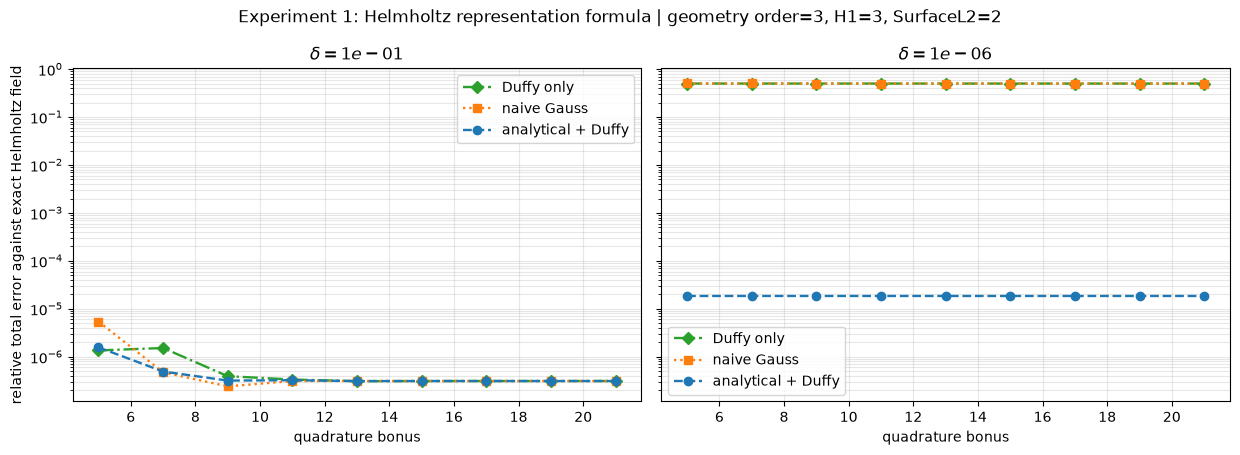

In [9]:
comparison_distances = [1e-1, 1e-6]
comparison_styles = {
    'Duffy only': {'marker': 'D', 'linestyle': '-.', 'color': 'tab:green', 'label': 'Duffy only'},
    'naive Gauss': {'marker': 's', 'linestyle': ':', 'color': 'tab:orange', 'label': 'naive Gauss'},
    'analytical + Duffy': {'marker': 'o', 'linestyle': '--', 'color': 'tab:blue', 'label': 'analytical + Duffy'},
}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), sharey=True)
for ax, distance in zip(axes, comparison_distances):
    for method, style in comparison_styles.items():
        data = quadrature_results[
            (quadrature_results['method'] == method)
            & np.isclose(quadrature_results['distance'], distance)
        ]
        ax.semilogy(
            data['bonus_intorder'],
            data['total_relative_error'],
            marker=style['marker'],
            linestyle=style['linestyle'],
            color=style['color'],
            linewidth=1.7,
            label=style['label'],
        )
    ax.set_xlabel('quadrature bonus')
    ax.set_title(rf'$\delta={distance:.0e}$')
    ax.grid(True, which='both', alpha=0.3)
    ax.legend(loc='best')

axes[0].set_ylabel('relative total error against exact Helmholtz field')
fig.suptitle(
    f'Experiment 1: Helmholtz representation formula | geometry order={curve_order}, '
    f'H1={trace_order}, SurfaceL2={flux_order}'
)
fig.tight_layout()
plt.savefig(
    OUTPUT_DIR / f"helmholtz_representation_comparison_curve={curve_order}_H1={trace_order}_L2={flux_order}.png",
    dpi=300,
)
plt.show()

## Interpretation and limitations

Experiment 1 tests the complete Helmholtz representation formula against the geometry-independent point-source solution. Its error contains propagated trace-interpolation error and quadrature error, and errors in $S(j_h)$ and $D(m_h)$ may cancel or reinforce. It is therefore a global quality measure for the direct representation, not a separate Single-Layer or Double-Layer accuracy theorem.

Experiment 2 uses the same geometry and the same interpolated traces, but its reference value is the discrete trace $m_h(y_0)$ in the exact Double-Layer jump relation. It therefore contains no trace-interpolation error. The remaining defect consists of finite-distance approach error and integration error. This makes it the sharper component-level diagnostic for the Double-Layer quadrature.

Together, the experiments are complementary: a method that performs well in both the total representation error and the discrete Double-Layer jump test has passed both a global and a component-level nearfield check. The experiments do not establish a uniform fixed-order error theorem, and the supporting-vertex path in Experiment 1 is geometry-specific. All generated CSV files and figures are written to `output/` with method names matching the paper: `naive Gauss`, `Duffy only`, and `analytical + Duffy`.

## Experiment 2: Helmholtz double-layer jump

This experiment reuses the same `source_mesh`, geometry order, trace spaces, and interpolated traces $m_h$ and $j_h$ as Experiment 1. We select an interior point $\boldsymbol y_0$ of one surface element and approach it from both sides along the mapped element normal:

$$
\boldsymbol x_\delta^{\rm out}=\boldsymbol y_0+\delta\boldsymbol n_h,
\qquad
\boldsymbol x_\delta^{\rm in}=\boldsymbol y_0-\delta\boldsymbol n_h.
$$

For the sign convention used here, the exact discrete jump is
$$
D(m_h)(\boldsymbol x_\delta^{\rm out})-D(m_h)(\boldsymbol x_\delta^{\rm in})\longrightarrow m_h(\boldsymbol y_0).
$$

Because the reference value is the discrete trace $m_h(\boldsymbol y_0)$ itself, this experiment contains no trace-interpolation error. It tests the Double-Layer quadrature and the approach-to-the-limit error directly. No Single-Layer normal-derivative experiment is included here.

In [10]:
from ngsolve import BND, TRIG
from ngsolve.fem import IntegrationRule

boundary_elements = [element for element in source_mesh.Elements(BND) if len(element.vertices) == 3]
centroid_rule = IntegrationRule(TRIG, 1)
mapped_centroids = source_mesh.MapToAllElements(centroid_rule, BND)
mapped_coordinates = np.column_stack((
    np.asarray(x(mapped_centroids)).reshape(-1),
    np.asarray(y(mapped_centroids)).reshape(-1),
    np.asarray(z(mapped_centroids)).reshape(-1),
))
if len(boundary_elements) != len(mapped_coordinates):
    raise ValueError('Experiment 2 currently expects a triangular surface mesh')

selected_index = max(
    range(len(boundary_elements)),
    key=lambda index: np.dot(
        mapped_coordinates[index] / np.linalg.norm(mapped_coordinates[index]),
        desired_direction,
    ),
)
selected_element = boundary_elements[selected_index]
selected_element_vertices = np.array(
    [source_mesh[vertex].point for vertex in selected_element.vertices],
    dtype=float,
)
surface_mesh_point = mapped_centroids[selected_index]
jump_surface_point = np.array(
    (x(surface_mesh_point), y(surface_mesh_point), z(surface_mesh_point)),
    dtype=float,
)
jump_normal = np.array(specialcf.normal(3)(surface_mesh_point), dtype=float)
jump_normal /= np.linalg.norm(jump_normal)
if np.dot(jump_normal, jump_surface_point) < 0:
    jump_normal *= -1.0

m_jump_exact = complex(m_h(surface_mesh_point))
print(f'selected jump element: {selected_element.nr}')
print(f'jump point y0: {tuple(jump_surface_point)}')
print(f'element normal: {tuple(jump_normal)}')
print(f'discrete exact jump m_h(y0): {m_jump_exact:.12e}')

selected jump element: 285
jump point y0: (np.float64(0.5694471135219545), np.float64(0.6289907765432878), np.float64(0.5292368787279559))
element normal: (np.float64(0.5694631058104161), np.float64(0.6289898683305495), np.float64(0.5292291721534945))
discrete exact jump m_h(y0): 5.928504225247e-01+8.524191035754e-01j


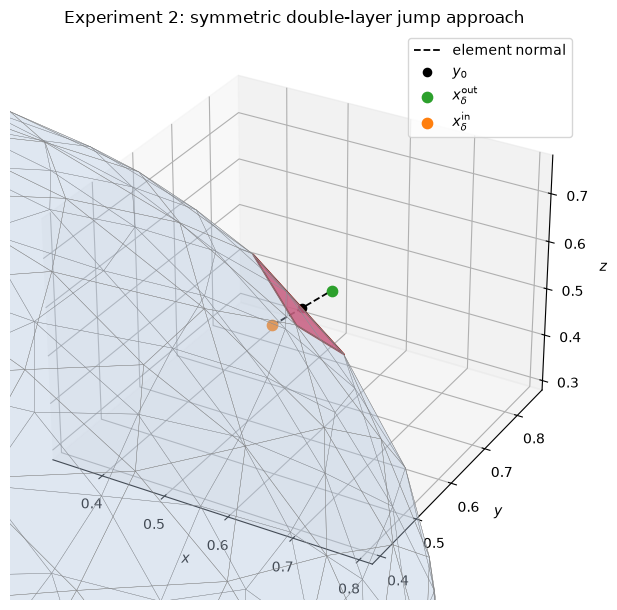

In [11]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

visualization_delta = 5e-2
point_out_vis = jump_surface_point + visualization_delta * jump_normal
point_in_vis = jump_surface_point - visualization_delta * jump_normal
all_triangles = [
    np.array([source_mesh[vertex].point for vertex in element.vertices], dtype=float)
    for element in boundary_elements
]
fig = plt.figure(figsize=(7.2, 6.2))
ax = fig.add_subplot(111, projection='3d')
ax.add_collection3d(Poly3DCollection(
    all_triangles, facecolor='lightsteelblue', edgecolor='gray', linewidth=0.25, alpha=0.22
))
ax.add_collection3d(Poly3DCollection(
    [selected_element_vertices], facecolor='crimson', edgecolor='darkred', linewidth=1.2, alpha=0.8
))
ax.plot(*np.column_stack((point_in_vis, point_out_vis)), color='black', linestyle='--', linewidth=1.3, label='element normal')
ax.scatter(*jump_surface_point, color='black', s=35, label=r'$y_0$')
ax.scatter(*point_out_vis, color='tab:green', s=55, label=r'$x_\delta^{\rm out}$')
ax.scatter(*point_in_vis, color='tab:orange', s=55, label=r'$x_\delta^{\rm in}$')
ax.set_xlim(jump_surface_point[0]-0.25, jump_surface_point[0]+0.25)
ax.set_ylim(jump_surface_point[1]-0.25, jump_surface_point[1]+0.25)
ax.set_zlim(jump_surface_point[2]-0.25, jump_surface_point[2]+0.25)
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
ax.set_zlabel('$z$')
ax.set_title('Experiment 2: symmetric double-layer jump approach')
ax.legend(loc='best')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'helmholtz_double_layer_jump_approach.png', dpi=300)
plt.show()

In [12]:
def helmholtz_double_layer_integrand(point):
    tx, ty, tz = point
    dx, dy, dz = tx-x, ty-y, tz-z
    distance = sqrt(dx**2 + dy**2 + dz**2)
    source_normal = ngs.specialcf.normal(3)
    normal_component = source_normal[0]*dx + source_normal[1]*dy + source_normal[2]*dz
    wave = exp(1j * kappa * distance)
    radial_derivative = wave * (1j*kappa*distance - 1) / (FOUR_PI * distance**3)
    return -m_h * normal_component * radial_derivative


def evaluate_double_layer_gauss(point, bonus):
    order = 2 + trace_order + bonus
    with TaskManager():
        value = Integrate(
            helmholtz_double_layer_integrand(point),
            source_mesh,
            definedon=source_region,
            order=order,
        )
    return complex(value)


def evaluate_double_layer_duffy(point, bonus):
    order = 2 + trace_order + bonus
    with TaskManager():
        value = duffy_quadrature.integrate(
            helmholtz_double_layer_integrand(point), point, order
        )
    return complex(value)


def evaluate_double_layer_star(point, bonus):
    _, value = evaluate_star(trace_space, m_h, flux_space, j_h, bonus, point)
    return value


def double_layer_jump_defect(value_out, value_in):
    return abs((value_out - value_in) - m_jump_exact) / abs(m_jump_exact)

### Jump data and method comparison

The jump reference is the value of the same discrete trace $m_h$ used in Experiment 1. Therefore the plotted defect contains quadrature error and finite-distance approach error, but no interpolation error. The Single-Layer potential is not analyzed separately here.

In [13]:
jump_rows = []
jump_methods = {
    'naive Gauss': evaluate_double_layer_gauss,
    'Duffy only': evaluate_double_layer_duffy,
    'analytical + Duffy': evaluate_double_layer_star,
}

for distance in evaluation_distances:
    point_out = jump_surface_point + distance * jump_normal
    point_in = jump_surface_point - distance * jump_normal
    for bonus in bonus_intorders:
        for method, evaluate in jump_methods.items():
            value_out = evaluate(point_out, bonus)
            value_in = evaluate(point_in, bonus)
            jump_rows.append({
                'method': method,
                'distance': distance,
                'bonus_intorder': bonus,
                'value_out': value_out,
                'value_in': value_in,
                'computed_jump': value_out - value_in,
                'exact_jump': m_jump_exact,
                'relative_jump_defect': double_layer_jump_defect(value_out, value_in),
            })

jump_results = pd.DataFrame(jump_rows)
jump_results.to_csv(OUTPUT_DIR / 'helmholtz_double_layer_jump_results.csv', index=False)
jump_results

,method,distance,bonus_intorder,value_out,value_in,computed_jump,exact_jump,relative_jump_defect
0,naive Gauss,0.100000,5,0.150064-0.220133j,-0.467487-1.146390j,0.617551+0.926257j,0.592850+0.852419j,7.498691e-02
1,Duffy only,0.100000,5,0.150065-0.220131j,-0.467488-1.146391j,0.617553+0.926260j,0.592850+0.852419j,7.499055e-02
2,analytical + Duffy,0.100000,5,0.150066-0.220130j,-0.467489-1.146392j,0.617554+0.926262j,0.592850+0.852419j,7.499264e-02
3,naive Gauss,0.100000,7,0.150066-0.220130j,-0.467489-1.146392j,0.617555+0.926263j,0.592850+0.852419j,7.499335e-02
4,Duffy only,0.100000,7,0.150066-0.220130j,-0.467489-1.146392j,0.617555+0.926262j,0.592850+0.852419j,7.499309e-02
...,...,...,...,...,...,...,...,...
157,Duffy only,0.000001,19,-0.156724-0.680891j,-0.159568-0.684980j,0.002844+0.004089j,0.592850+0.852419j,9.952032e-01
158,analytical + Duffy,0.000001,19,0.138279-0.256726j,-0.454572-1.109146j,0.592851+0.852420j,0.592850+0.852419j,7.958041e-07
159,naive Gauss,0.000001,21,-0.157661-0.682238j,-0.157799-0.682438j,0.000138+0.000199j,0.592850+0.852419j,9.997663e-01
160,Duffy only,0.000001,21,-0.156506-0.680578j,-0.159786-0.685294j,0.003280+0.004716j,0.592850+0.852419j,9.944674e-01


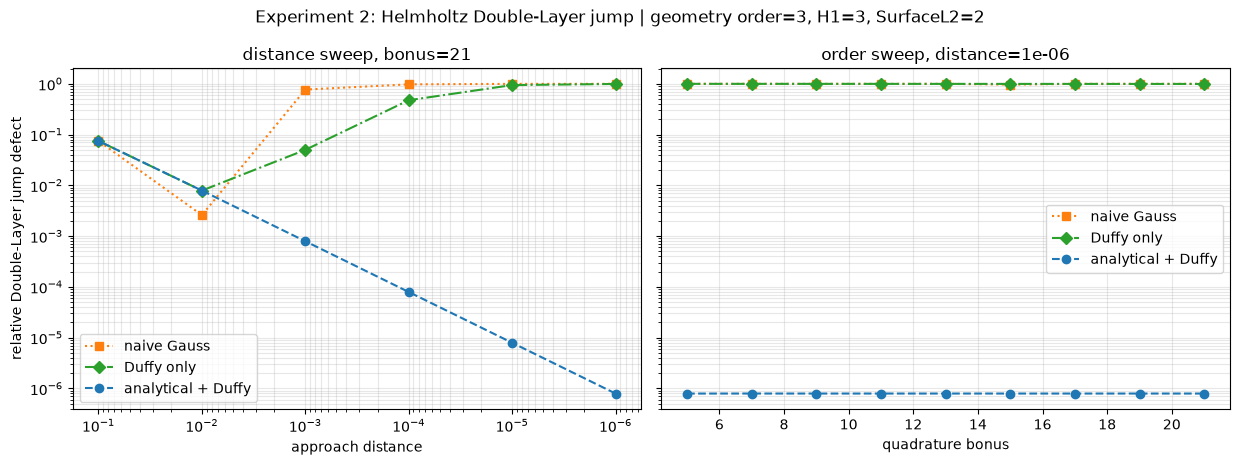

In [15]:
selected_bonus_intorder = bonus_intorders[-1]
jump_styles = {
    'naive Gauss': {'marker': 's', 'linestyle': ':', 'color': 'tab:orange'},
    'Duffy only': {'marker': 'D', 'linestyle': '-.', 'color': 'tab:green'},
    'analytical + Duffy': {'marker': 'o', 'linestyle': '--', 'color': 'tab:blue'},
}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.7), sharey=True)
for method, style in jump_styles.items():
    distance_data = jump_results[
        (jump_results['method'] == method)
        & (jump_results['bonus_intorder'] == selected_bonus_intorder)
    ].sort_values('distance')
    bonus_data = jump_results[
        (jump_results['method'] == method)
        & (jump_results['distance'] == min(evaluation_distances))
    ].sort_values('bonus_intorder')
    axes[0].loglog(
        distance_data['distance'], distance_data['relative_jump_defect'],
        marker=style['marker'], linestyle=style['linestyle'],
        color=style['color'], label=method,
    )
    axes[1].semilogy(
        bonus_data['bonus_intorder'], bonus_data['relative_jump_defect'],
        marker=style['marker'], linestyle=style['linestyle'],
        color=style['color'], label=method,
    )

axes[0].invert_xaxis()
axes[0].set_xlabel('approach distance')
axes[0].set_ylabel('relative Double-Layer jump defect')
axes[0].set_title(f'distance sweep, bonus={selected_bonus_intorder}')
axes[1].set_xlabel('quadrature bonus')
axes[1].set_title(f'order sweep, distance={min(evaluation_distances):.0e}')
for ax in axes:
    ax.grid(True, which='both', alpha=0.3)
    ax.legend(loc='best')
fig.suptitle(
    f'Experiment 2: Helmholtz Double-Layer jump | geometry order={curve_order}, '
    f'H1={trace_order}, SurfaceL2={flux_order}'
)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'helmholtz_double_layer_jump_defects.png', dpi=300)
plt.show()